# Case Study 2: Serine Proteases and the Invariant Catalytic Triad

This notebook investigates the evolutionary divergence and catalytic site preservation of the **Chymotrypsin-like Serine Protease** family:
- **TRY1_BOVIN**: Bovine Cationic Trypsinogen (*Bos taurus*, UniProt `P00760`)
- **CHEY_BOVIN**: Bovine Chymotrypsinogen A (*Bos taurus*, UniProt `P00766`)
- **EL1_HUMAN**: Human Neutrophil Elastase (*Homo sapiens*, UniProt `P08246`)

Unlike globins, which coordinate a heme cofactor, serine proteases cleave peptide bonds via a charge-relay network known as the **Catalytic Triad**:
- **Histidine** (acts as a general base/acid)
- **Aspartate** (stabilizes the charged histidine)
- **Serine** (provides the nucleophilic oxygen that attacks the carbonyl carbon)

In [1]:
# 1. Environment & Path Initialization
import sys
from pathlib import Path
import json

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster import hierarchy

# Import unified engine components
from src.data_loader import load_sequences
from src.aligner import compute_similarity_matrix
from src.clustering import compute_hierarchical_linkage
from src.msa import progressive_msa
from src.entropy import compute_msa_conservation, plot_conservation_profile
from src.active_site_analyzer import inspect_active_sites
from src.structure_viewer import fetch_pdb_file
from src.phylogeny import build_phylogenetic_tree, export_newick, plot_phylogenetic_tree, render_interactive_tree
import py3Dmol


sns.set_theme(style="whitegrid", font_scale=1.05)
%matplotlib inline
print(f"Project root configured: {project_root.resolve()}")

Project root configured: D:\Bioinformatics\Protein Similarity Analysis


## Step 1: Load Full-Length Canonical Precursor Sequences

We load full precursor sequences from `data/raw/proteases.fasta` to maintain coordinate parity with Swiss-Prot annotation records.

In [2]:
fasta_path = project_root / "data" / "raw" / "proteases.fasta"
records = load_sequences(fasta_path)

summary = []
for r in records:
    summary.append({
        "Protein ID": r.id,
        "Total Length (aa)": len(r.seq),
        "N-terminus": str(r.seq[:12]),
        "C-terminus": str(r.seq[-12:])
    })

pd.DataFrame(summary)

,Protein ID,Total Length (aa),N-terminus,C-terminus
0,TRY1_BOVIN,246,MKTFIFLALLGA,YVSWIKQTIASN
1,CHEY_BOVIN,263,MAFLWLLSCWAL,LVNWVQQTLAAN
2,EL1_HUMAN,268,MTLGRRLACLFL,HPRDPDPASRTH


## Step 2: Global Alignment, Identity Matrix, and Divergence

We calculate pairwise global alignment identity using BLOSUM62 and reconstruct the UPGMA dendrogram.

Pairwise % Sequence Identity:


,TRY1_BOVIN,CHEY_BOVIN,EL1_HUMAN
TRY1_BOVIN,100.0%,43.9%,34.6%
CHEY_BOVIN,43.9%,100.0%,32.3%
EL1_HUMAN,34.6%,32.3%,100.0%


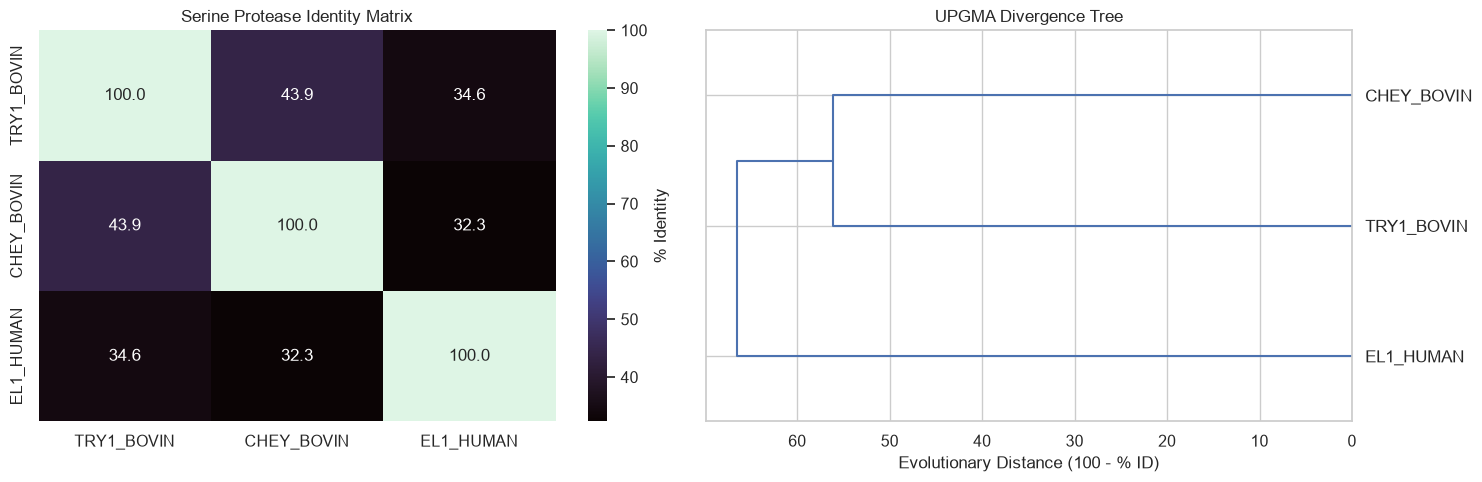

In [3]:
df_identity, df_distance = compute_similarity_matrix(records)

print("Pairwise % Sequence Identity:")
display(df_identity.style.background_gradient(cmap="mako", axis=None).format("{:.1f}%"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Heatmap
sns.heatmap(df_identity, annot=True, fmt=".1f", cmap="mako", cbar_kws={'label': '% Identity'}, ax=axes[0])
axes[0].set_title("Serine Protease Identity Matrix", fontsize=12)

# UPGMA Dendrogram
linkage = compute_hierarchical_linkage(df_distance, method="average")
hierarchy.dendrogram(linkage, labels=list(df_identity.index), orientation="left", ax=axes[1])
axes[1].set_title("UPGMA Divergence Tree", fontsize=12)
axes[1].set_xlabel("Evolutionary Distance (100 - % ID)")

plt.tight_layout()
plt.show()

## Step 3: Progressive MSA and Shannon Entropy Profiling

We run progressive MSA across the three proteases and compute column-by-column Shannon Entropy to evaluate whether active site positions show higher conservation than the rest of the protein chain.

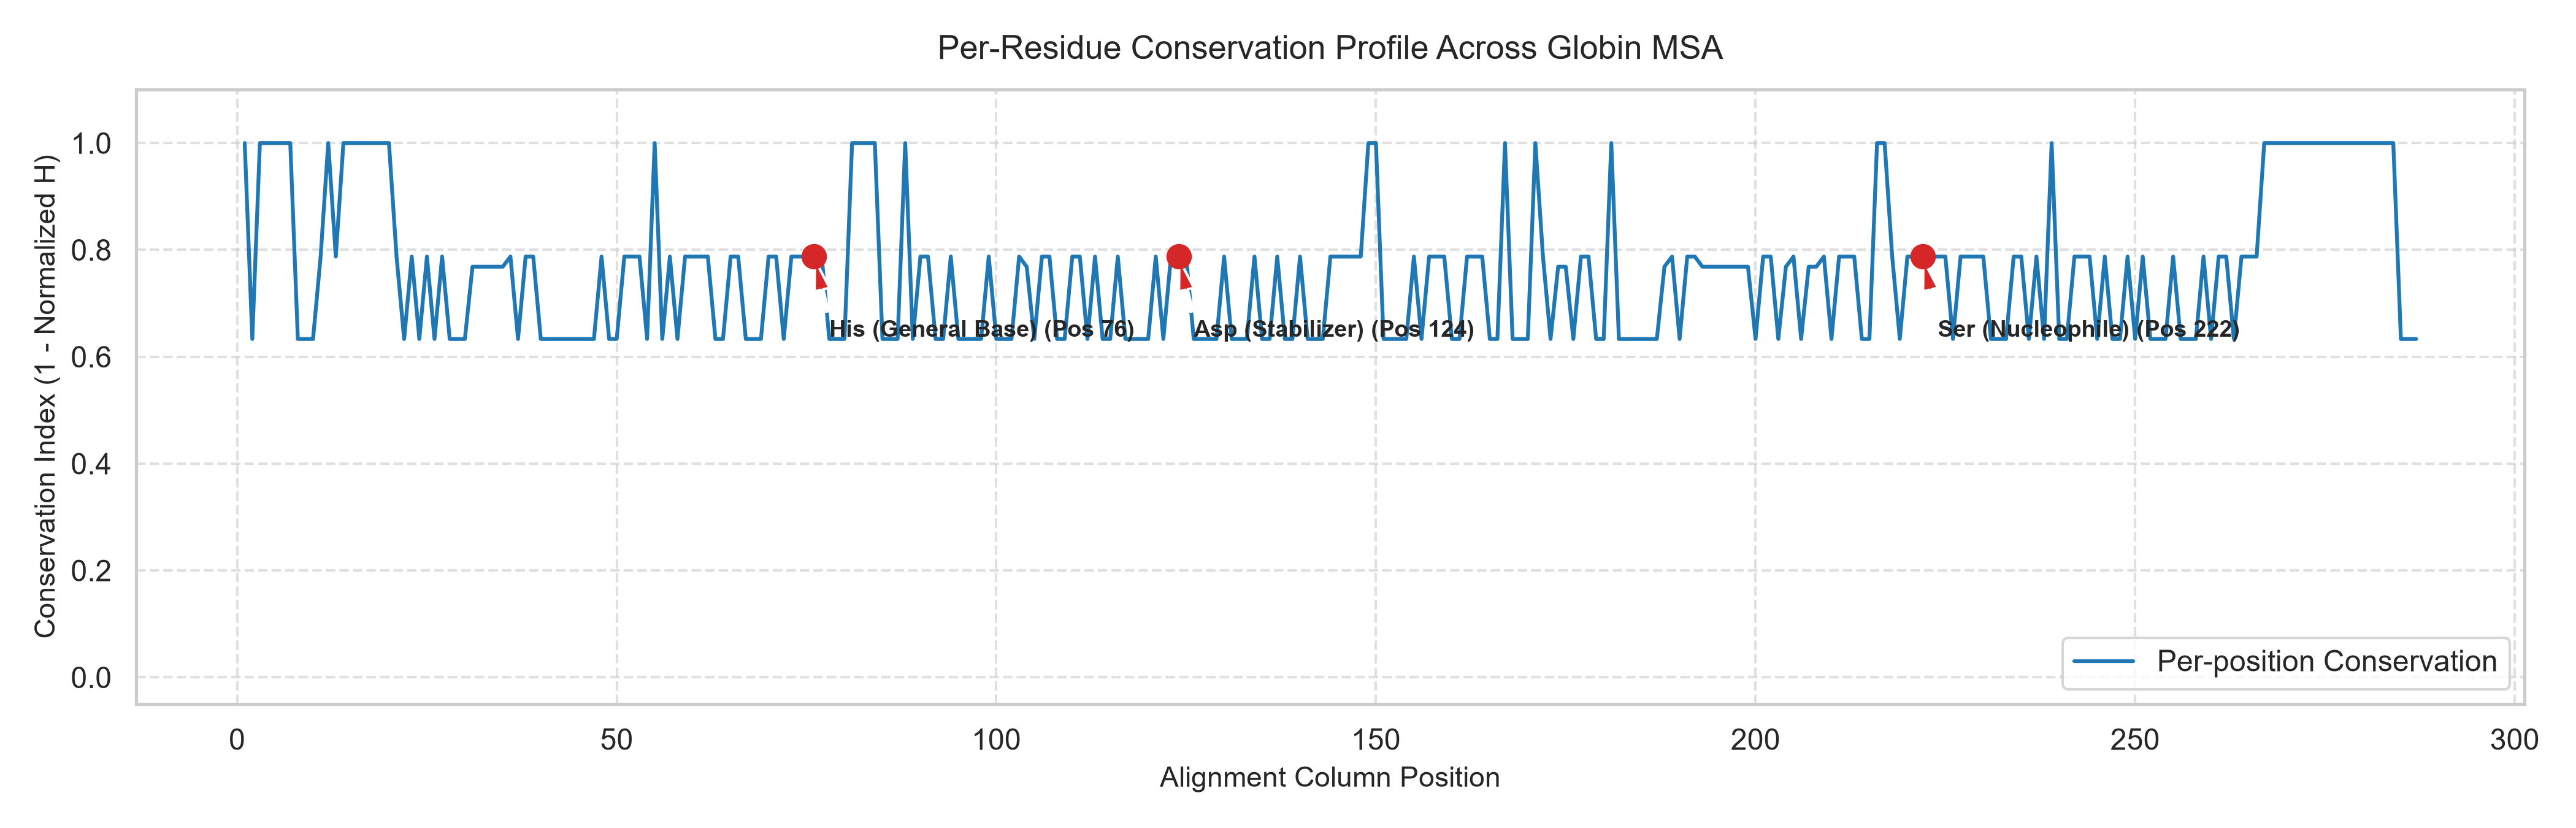

In [4]:
# 1. Compute MSA
msa_records = progressive_msa(records)

# 2. Compute Conservation
df_entropy = compute_msa_conservation(msa_records)

# 3. Locate the three catalytic residues in the alignment
# In the aligned precursor grid, the catalytic columns correspond to the aligned positions of Trypsin His63, Asp107, Ser200
ref_aligned = str(msa_records[0].seq)
def get_msa_col(target_raw_pos):
    raw_c = 0
    for idx, char in enumerate(ref_aligned):
        if char != "-":
            raw_c += 1
        if raw_c == target_raw_pos:
            return idx + 1
    return None

his_col = get_msa_col(63)
asp_col = get_msa_col(107)
ser_col = get_msa_col(200)

highlights = [
    (his_col, "His (General Base)"),
    (asp_col, "Asp (Stabilizer)"),
    (ser_col, "Ser (Nucleophile)")
]

entropy_fig_path = project_root / "results_proteases" / "figures" / "conservation_profile.png"
plot_conservation_profile(df_entropy, highlights, entropy_fig_path)

# Display profile inline
from IPython.display import Image
Image(filename=entropy_fig_path)    

## Step 4: Catalytic Triad Conservation via UniProt Swiss-Prot Config

We load official annotations fetched from UniProt accession `P00760` (`config/sites/uniprot_trypsin.json`) and run our universal tolerance-aware active-site analyzer.

In [5]:
config_path = project_root / "config" / "sites" / "uniprot_trypsin.json"
with open(config_path, "r", encoding="utf-8") as f:
    uniprot_cfg = json.load(f)

print(f"Reference: {uniprot_cfg['reference_id']} ({uniprot_cfg['source']})")

df_triad = inspect_active_sites(
    records=records,
    ref_id=uniprot_cfg["reference_id"],
    sites_config=uniprot_cfg["sites"],
    window_tolerance=2
)

# Render formatted dataframe
display(
    df_triad.style.map(
        lambda val: "background-color: #c6efce; color: #006100; font-weight: bold;" if val is True else "",
        subset=[col for col in df_triad.columns if col.endswith("_Conserved")]
    )
)

Reference: TRY1_BOVIN (UniProtKB/Swiss-Prot)


,Protein,Active_site_63_Charge_relay_system_Residue,Active_site_63_Charge_relay_system_Effect,Active_site_63_Charge_relay_system_Conserved,Active_site_107_Charge_relay_system_Residue,Active_site_107_Charge_relay_system_Effect,Active_site_107_Charge_relay_system_Conserved,Active_site_200_Charge_relay_system_Residue,Active_site_200_Charge_relay_system_Effect,Active_site_200_Charge_relay_system_Conserved,Binding_site_75__Residue,Binding_site_75__Effect,Binding_site_75__Conserved,Binding_site_77__Residue,Binding_site_77__Effect,Binding_site_77__Conserved,Binding_site_80__Residue,Binding_site_80__Effect,Binding_site_80__Conserved,Binding_site_85__Residue,Binding_site_85__Effect,Binding_site_85__Conserved,Binding_site_200__Residue,Binding_site_200__Effect,Binding_site_200__Conserved
0,TRY1_BOVIN,H63,Reference,True,D107,Reference,True,S200,Reference,True,E75,Reference,True,N77,Reference,True,V80,Reference,True,E85,Reference,True,S200,Reference,True
1,CHEY_BOVIN,H75,Conserved Identical,True,D120,Conserved Identical,True,S213,Conserved Identical,True,V78,Diverged (Acidic (-) -> Hydrophobic Aliphatic),False,T80,Conservative Swap (Polar Neutral),True,V83,Conserved Identical,True,E88,Conserved Identical,True,S213,Conserved Identical,True
2,EL1_HUMAN,H71,Conserved Identical,True,D118,Conserved Identical,True,S203,Conserved Identical,True,A87,Diverged (Acidic (-) -> Hydrophobic Aliphatic),False,N89,Conserved Identical,True,R92,Diverged (Hydrophobic Aliphatic -> Basic (+)),False,R97,Diverged (Acidic (-) -> Basic (+)),False,S203,Conserved Identical,True


## Step 5: 3D Geometric Assembly of the Catalytic Triad

While sequence alignment shows His, Asp, and Ser separated by tens of amino acids along the 1D linear chain (positions ~63, ~107, ~200), in tertiary 3D structure they must converge within hydrogen-bonding distance ($< 3.2\ \text{Å}$).

We fetch the Bovine Trypsin structure (**PDB: 4J2Y**) to visualize this spatial configuration.

In [6]:
pdb_text = fetch_pdb_file("4J2Y")

viewer = py3Dmol.view(width=780, height=520)
viewer.addModel(pdb_text, "pdb")

# Gray cartoon backbone
viewer.setStyle({}, {"cartoon": {"color": "#c8d6e5", "opacity": 0.85}})

# In PDB 4J2Y, mature chain numbering is used: His57, Asp102, Ser195
triad_mature = [57, 102, 195]

viewer.addStyle(
    {"resi": triad_mature},
    {"stick": {"colorscheme": "magentaCarbon", "radius": 0.28}}
)

# Position labels
viewer.addLabel("His57 (Base)", {"resi": 57}, {"backgroundColor": "#222222", "fontColor": "#ffffff", "fontSize": 11})
viewer.addLabel("Asp102 (Acid)", {"resi": 102}, {"backgroundColor": "#222222", "fontColor": "#ffffff", "fontSize": 11})
viewer.addLabel("Ser195 (Nucleophile)", {"resi": 195}, {"backgroundColor": "#222222", "fontColor": "#ffffff", "fontSize": 11})

viewer.zoomTo({"resi": triad_mature})
viewer.render()
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

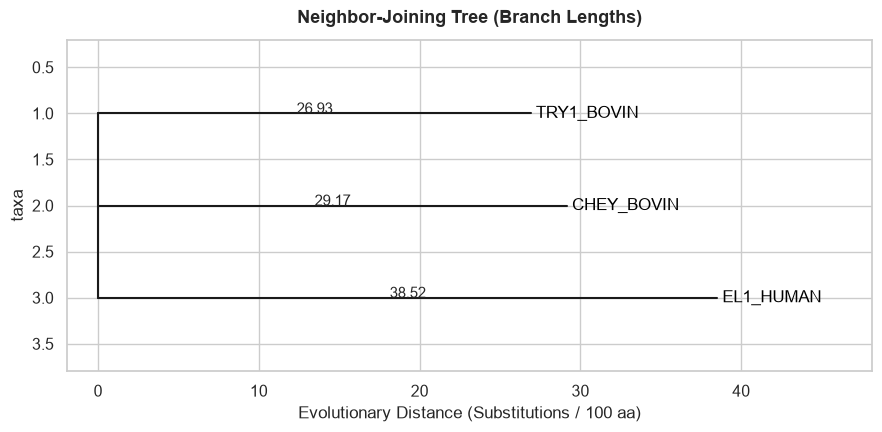

In [7]:
# 1. Build Neighbor-Joining tree directly from the existing distance matrix
nj_tree = build_phylogenetic_tree(df_distance, method="nj")

# 2. Export standard Newick tree file
export_newick(nj_tree, project_root / "results" / "trees" / "phylogeny_nj.nwk")

# 3. Draw tree showing individual branch divergence lengths
plot_phylogenetic_tree(nj_tree, title="Neighbor-Joining Tree (Branch Lengths)")
plt.show()

In [8]:
# 1. Compute tree from the existing distance matrix
nj_tree = build_phylogenetic_tree(df_distance, method="nj")

# 2. Render Interactive Circular / Radial Cladogram
fig_circular = render_interactive_tree(
    nj_tree, 
    layout="circular", 
    title="Interactive Radial Cladogram (Hover for Branch Distances)"
)
fig_circular.show()

# 3. Render Interactive Rectangular Tree (with axes and hover cards)
fig_rect = render_interactive_tree(
    nj_tree, 
    layout="rectangular", 
    title="Interactive Rectangular Tree (Hover for Branch Distances)"
)
fig_rect.show()

### Key Biological Takeaways
1. **Low Overall Sequence Identity:** Trypsin, chymotrypsin, and neutrophil elastase share only ~35–42% overall sequence identity, reflecting ancient evolutionary divergence and distinct substrate specificities (Trypsin cuts after basic Lys/Arg, Chymotrypsin cuts after bulky aromatics, Elastase cuts after small aliphatics).
2. **Absolute Functional Invariance:** Despite divergence across the structural scaffold, all three catalytic triad members (**His**, **Asp**, **Ser**) show **100% conservation** across all three enzymes.
3. **Sequence vs. Structure:** In the linear sequence, the triad residues are distributed far apart. The 3D model shows that the tertiary $\beta$-barrel fold brings them into close proximity to assemble the functional catalytic pore.